In [5]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict


In [11]:
# define state

class BMIState(TypedDict):
    height_m: float
    weight_kg: float
    bmi: float
    category: str

In [4]:
def calculate_bmi(state: BMIState) -> BMIState:
    weight = state["weight_kg"]
    height = state["height_m"]
    bmi = weight / (height ** 2)
    state["bmi"] = round(bmi, 2)
    return state

In [12]:
def determine_category(state: BMIState) -> BMIState:
    bmi = state["bmi"]
    if bmi < 18.5:
        state["category"] = "Underweight"
    elif bmi < 24.9:
        state["category"] = "Normal weight"
    elif bmi < 29.9:
        state["category"] = "Overweight"
    else:
        state["category"] = "Obesity"
    return state

In [13]:
# define graph

graph = StateGraph(BMIState)

# add nodes to the graph

graph.add_node("calculate_bmi", calculate_bmi)
graph.add_node("determine_category", determine_category)

# add edges to the graph

graph.add_edge(START, "calculate_bmi")
graph.add_edge("calculate_bmi", "determine_category")
graph.add_edge("determine_category", END)

# compile the graph

workflow = graph.compile()

In [15]:
# execute the graph

input_state = {"height_m": 1.75, "weight_kg": 70}
output_state = workflow.invoke(input_state)

print(output_state)

{'height_m': 1.75, 'weight_kg': 70, 'bmi': 22.86, 'category': 'Normal weight'}


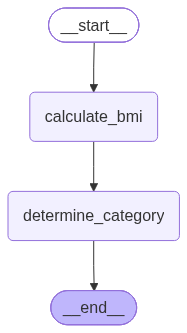

In [14]:
from IPython.display import Image

Image(workflow.get_graph().draw_mermaid_png())
